In [1]:
import sys
sys.path.insert(0, "../src")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from sklearn.ensemble import HistGradientBoostingClassifier

from features import SR, SCALAR_FEATURES, MFCC_FEATURES, CONTEXT_FEATURES, extract_features
from dataset import load_wav, list_clips, speech_labels, mix, build_frame_table, SNR_LEVELS, DATA_DIR
from evaluate import scores, fit_model

results_dir = Path("../results")
results_dir.mkdir(exist_ok=True)

BEST_SET = SCALAR_FEATURES + MFCC_FEATURES + CONTEXT_FEATURES


def fit_trees(table, features, target="speech"):
    """Gradient boosting: many small decision trees, so it can learn rules like 'loud AND not pitched'."""
    model = HistGradientBoostingClassifier(max_iter=200, class_weight="balanced", random_state=0)
    model.fit(table[features].values, table[target].values)
    return model

In [2]:
import sys
sys.path.insert(0, "../src")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from sklearn.ensemble import HistGradientBoostingClassifier

from features import SR, SCALAR_FEATURES, MFCC_FEATURES, CONTEXT_FEATURES, extract_features
from dataset import load_wav, list_clips, speech_labels, mix, build_frame_table, SNR_LEVELS, DATA_DIR
from evaluate import scores, fit_model

results_dir = Path("../results")
results_dir.mkdir(exist_ok=True)

BEST_SET = SCALAR_FEATURES + MFCC_FEATURES + CONTEXT_FEATURES


def fit_trees(table, features, target="speech"):
    """Gradient boosting: many small decision trees, so it can learn rules like 'loud AND not pitched'."""
    model = HistGradientBoostingClassifier(max_iter=200, class_weight="balanced", random_state=0)
    model.fit(table[features].values, table[target].values)
    return model

Ne yapıyor:

İlk bölüm: Önceki notebook’larla aynı kütüphaneler ve kendi dosyalarımız. İki yeni şey var:
HistGradientBoostingClassifier: Dün geceki karar ağacı modeli.
DATA_DIR: data klasörünün yolu. Ek gürültüleri bulmak için gerekecek.
BEST_SET: 33 feature’ın hepsi. Notebook 03'te en iyi çıkan set.
fit_trees(...): Gradient boosting modelini kuran kısa bir fonksiyon. Dün gece bunu hücrenin içine doğrudan yazmıştık; bu notebook’ta altı kez kullanacağımız için fonksiyon yaptık. İçindeki ayarlar dünküyle aynı.

In [3]:
train = build_frame_table("train")
test = build_frame_table("test")

linear_model = fit_model(train, BEST_SET, "speech")
tree_model = fit_trees(train, BEST_SET)

for name, model in [("logistic regression", linear_model), ("gradient boosting", tree_model)]:
    result = scores(test["speech"].values, model.predict(test[BEST_SET].values))
    print(f"{name:20s} balanced accuracy on the whole test set: {result['balanced_acc']:.3f}")

logistic regression  balanced accuracy on the whole test set: 0.922
gradient boosting    balanced accuracy on the whole test set: 0.934


Ne yapıyor:

İlk iki satır: Train ve test tablolarını kurar. Notebook 03'teki hücre 2'nin aynısı.
linear_model: Logistic regression, 33 feature, “konuşma var mı” sorusu için.
tree_model: Gradient boosting, aynı 33 feature.
Döngü: İki modelin bütün test verisindeki balanced accuracy’sini yazar.

Neden yeniden kuruyoruz: Her notebook kendi başına çalışabilmeli. Hoca yalnızca notebook 04'ü açıp çalıştırırsa notebook 03'ün belleğindeki tablolar onda olmaz.

Beklenen: İki satır. Dün geceki sayılarla aynı olmalı: logistic regression 0,922, gradient boosting 0,934. Aynı veri, aynı ayarlar; farklı çıkarsa bir şey değişmiş demektir.

In [4]:
zero_db = test[test["condition"] == "speech + noise 0 dB"]
pause = (zero_db["speech"] == 0).values            # pause frames: no speech, only (loud) noise

zero_db_predicted = linear_model.predict(zero_db[BEST_SET].values)
per_clip = pd.Series(zero_db_predicted[pause]).groupby(zero_db["clip"].values[pause]).mean().sort_values(ascending=False)
display(per_clip.round(2).to_frame("share of pause frames called speech (0 dB)"))

,share of pause frames called speech (0 dB)
8.wav,1.00
18.wav,0.93
14.wav,0.88
5.wav,0.75
10.wav,0.75
7.wav,0.57
19.wav,0.49
4.wav,0.48
1.wav,0.45
12.wav,0.44


Soru: 0 dB’de model duraklamaların yarısına “konuşma” diyordu. Bu her kayıtta mı oluyor?

Ne yapıyor:

zero_db: Test verisinden yalnızca 0 dB karışımlar.
pause: Her parça için: duraklama mı? Duraklama, konuşmanın olmadığı, yalnızca gürültünün olduğu parça. Burada doğru cevap “konuşma yok”.
zero_db_predicted: Logistic regression’ın her parça için tahmini (1 = konuşma, 0 = değil).
per_clip: Yalnızca duraklama parçalarını alır, kayıt kayıt gruplar ve her kayıtta tahminlerin ortalamasını hesaplar. Tahminler 0 ve 1 olduğu için ortalama şu demek: o kayıttaki duraklamaların yüzde kaçına “konuşma” denmiş. En kötüden iyiye sıralar.

Beklenen: Dün geceki listenin aynısı. En üstte 8, 18, 14 (1,00 / 0,93 / 0,88), en altta 6 (0,09).

Bu hücrenin rolü: Soruşturmanın başlangıç noktası. Sorunun bütün kayıtlara yayılmadığını, bazı kayıtlarda yoğunlaştığını gösteriyor. Sen o kayıtları dinleyip kuş sesini buldun.

Bright noise clips in test : ['8.wav', '18.wav', '14.wav']
Bright noise clips in train: ['18.wav', '26.wav', '20.wav'] (3 of 30)


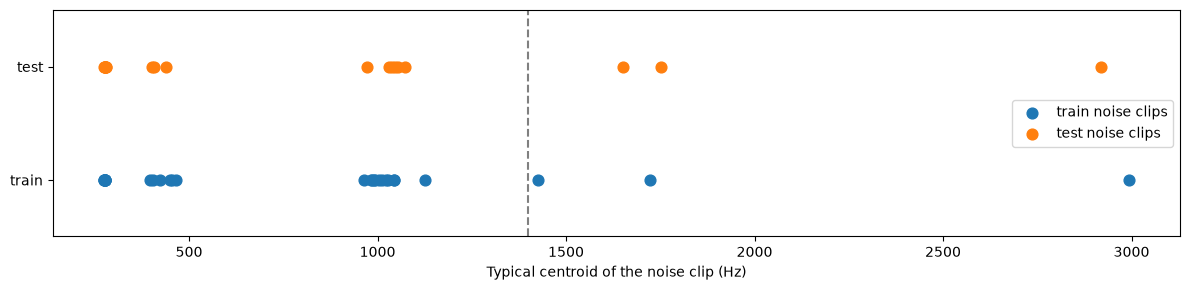

In [5]:
def noise_brightness(table):
    """Typical centroid (Hz) of every noise-only clip, sorted from dull to bright."""
    noise_part = table[table["condition"] == "noise only"]
    return noise_part.groupby("clip")["centroid"].median().sort_values()

BRIGHT_HZ = 1400                                   # we call a noise clip "bright" above this centroid
train_centroid = noise_brightness(train)
test_centroid = noise_brightness(test)
bright_test_clips = test_centroid[test_centroid > BRIGHT_HZ].index.tolist()
bright_train_clips = train_centroid[train_centroid > BRIGHT_HZ].index.tolist()
print("Bright noise clips in test :", bright_test_clips)
print("Bright noise clips in train:", bright_train_clips, f"({len(bright_train_clips)} of {len(train_centroid)})")

fig, ax = plt.subplots(figsize=(12, 3))
ax.scatter(train_centroid.values, np.zeros(len(train_centroid)), label="train noise clips", s=60)
ax.scatter(test_centroid.values, np.ones(len(test_centroid)), label="test noise clips", s=60)
ax.axvline(BRIGHT_HZ, color="grey", linestyle="--")
ax.set_yticks([0, 1]); ax.set_yticklabels(["train", "test"]); ax.set_ylim(-0.5, 1.5)
ax.set_xlabel("Typical centroid of the noise clip (Hz)"); ax.legend(loc="center right")
plt.tight_layout(); plt.show()

In [6]:
noise_test = test[test["condition"] == "noise only"]
dull_test_clips = test_centroid[test_centroid < 300].index.tolist()
columns = ["harmonicity", "centroid", "zcr", "energy_db_std", "harmonicity_std"]
compare = pd.DataFrame({
    "bright noise": noise_test[noise_test["clip"].isin(bright_test_clips)][columns].median(),
    "dull noise": noise_test[noise_test["clip"].isin(dull_test_clips)][columns].median(),
    "speech (clean)": test[(test["klass"] == "speech") & (test["condition"] == "clean speech")][columns].median(),
})
display(compare.round(3))

,bright noise,dull noise,speech (clean)
harmonicity,0.205,0.236,0.512
centroid,1820.279,277.704,1097.034
zcr,0.158,0.025,0.060
energy_db_std,1.012,1.594,6.472
harmonicity_std,0.059,0.107,0.151


In [ ]:
zero_db = test[test["condition"] == "speech + noise 0 dB"]
pause = (zero_db["speech"] == 0).values            # pause frames: no speech, only (loud) noise

zero_db_predicted = linear_model.predict(zero_db[BEST_SET].values)
per_clip = pd.Series(zero_db_predicted[pause]).groupby(zero_db["clip"].values[pause]).mean().sort_values(ascending=False)
display(per_clip.round(2).to_frame("share of pause frames called speech (0 dB)"))

,share of pause frames called speech (0 dB)
8.wav,1.00
18.wav,0.93
14.wav,0.88
5.wav,0.75
10.wav,0.75
7.wav,0.57
19.wav,0.49
4.wav,0.48
1.wav,0.45
12.wav,0.44


In [7]:
bright = zero_db["clip"].isin(bright_test_clips).values


def zero_db_errors(model, features):
    """False alarms on bright / other noise and found speech, on the 0 dB test mixtures."""
    predicted = model.predict(zero_db[features].values)
    return {
        "false alarm, bright noise": predicted[pause & bright].mean(),
        "false alarm, other noise": predicted[pause & ~bright].mean(),
        "speech found": predicted[~pause].mean(),
    }

no_brightness = [f for f in SCALAR_FEATURES if f not in ("centroid", "zcr")]
candidates = {
    "energy only": ["energy_db"],
    "7 scalar": SCALAR_FEATURES,
    "scalar without centroid, zcr": no_brightness,
    "all 33": BEST_SET,
}
table_a5 = pd.DataFrame({name: zero_db_errors(fit_model(train, features, "speech"), features)
                         for name, features in candidates.items()}).T
display(table_a5.round(3))

,"false alarm, bright noise","false alarm, other noise",speech found
energy only,0.989,1.000,1.000
7 scalar,0.987,0.753,0.969
"scalar without centroid, zcr",0.986,0.861,0.977
all 33,0.943,0.381,0.944


Extra noise clips: 60
Extra clips that are copies of existing clips: none
Bright extra clips: 15 of 60


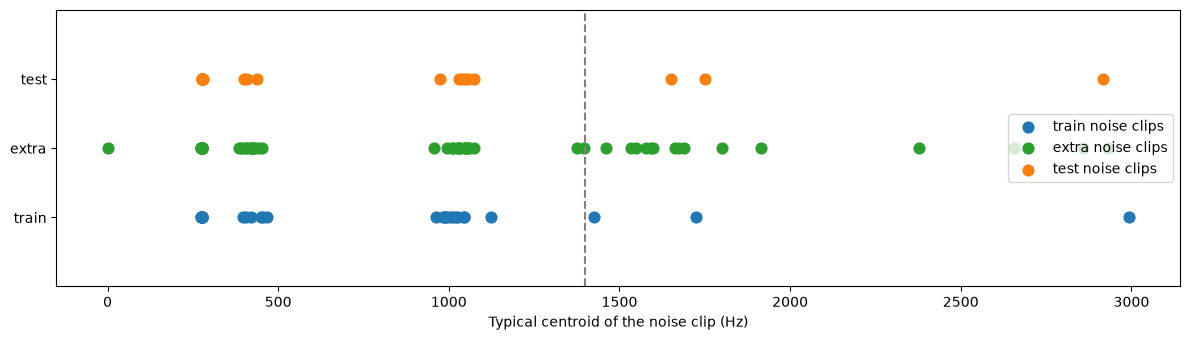

In [8]:
extra_files = sorted((DATA_DIR / "train" / "noise_extra").glob("*.wav"))
extra_noises = {path.name: load_wav(path) for path in extra_files}
print("Extra noise clips:", len(extra_noises))

# Copy check: is an extra clip identical to a clip we already have? (compare the first 2 seconds)
known = {f"train/{p.name}": load_wav(p)[:2 * SR] for p in list_clips("train", "noise_only")}
known.update({f"test/{p.name}": load_wav(p)[:2 * SR] for p in list_clips("test", "noise_only")})
copies = [(name, other) for name, y in extra_noises.items() for other, start in known.items()
          if len(start) == 2 * SR and np.allclose(y[:2 * SR], start, atol=1e-3)]
print("Extra clips that are copies of existing clips:", copies if copies else "none")

extra_centroid = pd.Series({name: np.median(extract_features(y)["centroid"]) for name, y in extra_noises.items()}).sort_values()
bright_extra = extra_centroid[extra_centroid > BRIGHT_HZ].index.tolist()
print("Bright extra clips:", len(bright_extra), "of", len(extra_centroid))

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.scatter(train_centroid.values, np.zeros(len(train_centroid)), label="train noise clips", s=60)
ax.scatter(extra_centroid.values, np.full(len(extra_centroid), 0.5), label="extra noise clips", s=60, color="tab:green")
ax.scatter(test_centroid.values, np.ones(len(test_centroid)), label="test noise clips", s=60)
ax.axvline(BRIGHT_HZ, color="grey", linestyle="--")
ax.set_yticks([0, 0.5, 1]); ax.set_yticklabels(["train", "extra", "test"]); ax.set_ylim(-0.5, 1.5)
ax.set_xlabel("Typical centroid of the noise clip (Hz)"); ax.legend(loc="center right")
plt.tight_layout(); plt.show()

In [9]:
loudness = {name: np.sqrt(np.mean(y ** 2)) for name, y in extra_noises.items()}
silent = [name for name, rms in loudness.items() if rms < 1e-4]
print("Silent extra clips removed:", silent if silent else "none")
extra_noises = {name: y for name, y in extra_noises.items() if name not in silent}


def frames_for_extra_noise(noises):
    """Same recipe as build_frame_table: the noise alone, and the noise mixed into a clean train clip at every SNR."""
    clean_files = list_clips("train", "clean_speech")
    tables = []
    for k, (name, noise) in enumerate(noises.items()):
        table = extract_features(noise)
        table["klass"], table["condition"], table["clip"] = "noise", "noise only", "extra_" + name
        tables.append(table)

        clean = load_wav(clean_files[k % len(clean_files)])      # reuse the train speech clips in turn
        is_speech = speech_labels(clean)
        for snr_db in SNR_LEVELS:
            table = extract_features(mix(clean, noise, snr_db))
            table["klass"] = np.where(is_speech, "speech", "noise")
            table["condition"], table["clip"] = f"speech + noise {snr_db} dB", "extra_" + name
            tables.append(table)
    extra = pd.concat(tables, ignore_index=True)
    extra["audio"] = (extra["klass"] != "silence").astype(int)
    extra["speech"] = (extra["klass"] == "speech").astype(int)
    return extra

extra_all = frames_for_extra_noise(extra_noises)
extra_dull = extra_all[~extra_all["clip"].isin(["extra_" + name for name in bright_extra])]
print("Rows: train", len(train), "| extra (all)", len(extra_all), "| extra (dull only)", len(extra_dull))

Silent extra clips removed: none
Rows: train 299700 | extra (all) 479520 | extra (dull only) 359640


In [10]:
training_sets = {
    "1. original train": train,
    "2. + all extra noise": pd.concat([train, extra_all], ignore_index=True),
    "3. + extra noise without the bright ones": pd.concat([train, extra_dull], ignore_index=True),
}

rows = []
for set_name, table in training_sets.items():
    for model_name, fit in [("logistic regression", lambda t: fit_model(t, BEST_SET, "speech")),
                            ("gradient boosting", lambda t: fit_trees(t, BEST_SET))]:
        model = fit(table)
        row = {"training data": set_name, "model": model_name, **zero_db_errors(model, BEST_SET)}
        row["balanced_acc, whole test set"] = scores(test["speech"].values, model.predict(test[BEST_SET].values))["balanced_acc"]
        rows.append(row)
table_b3 = pd.DataFrame(rows).set_index(["model", "training data"]).sort_index()
display(table_b3.round(3))
table_b3.round(4).to_csv(results_dir / "table6_more_noise.csv")

false alarm, bright noise  \
model               training data                                                         
gradient boosting   1. original train                                             0.907   
                    2. + all extra noise                                          0.416   
                    3. + extra noise without the bright ones                      0.888   
logistic regression 1. original train                                             0.943   
                    2. + all extra noise                                          0.825   
                    3. + extra noise without the bright ones                      0.951   

                                                              false alarm, other noise  \
model               training data                                                        
gradient boosting   1. original train                                            0.235   
                    2. + all extra noise                                         0.255   
                    3. + extra noise without the bright ones                     0.242   
logistic regression 1. original train                                            0.381   
                    2. + all extra noise                                         0.375   
                    3. + extra noise without the bright ones                     0.398   

                                                              speech found  \
model               training data                                            
gradient boosting   1. original train                                0.936   
                    2. + all extra noise                             0.923   
                    3. + extra noise without the bright ones         0.933   
logistic regression 1. original train                                0.944   
                    2. + all extra noise                             0.933   
                    3. + extra noise without the bright ones         0.948   

                                                              balanced_acc, whole test set  
model               training data                                                           
gradient boosting   1. original train                                                0.934  
                    2. + all extra noise                                             0.938  
                    3. + extra noise without the bright ones                         0.935  
logistic regression 1. original train                                                0.922  
                    2. + all extra noise                                             0.922  
                    3. + extra noise without the bright ones                         0.923

Tiz gürültüde yanlış alarm (asıl sayı)
Model	1. Eski train	2. + bütün ek gürültü	3. + tizsiz ek gürültü
Gradient boosting	0,907	0,416	0,888
Logistic regression	0,943	0,825	0,951

Gradient boosting: Ek gürültülerle eğitince tiz gürültüde yanlış alarm 0,907'den 0,416'ya indi. Yarıdan fazla azaldı.

Kontrol grubu (3. satır): Aynı ek veriyi tiz gürültüler çıkarılmış haliyle verince hiçbir şey değişmedi: 0,888. Oysa bu da 360 bin satırlık ek veri.

Koyduğumuz kurala göre: 2 belirgin düştü, 3 düşmedi → işe yarayan tiz örnekler. “Daha çok veri” tek başına yetmiyor; doğru türden veri gerekiyor.

Logistic regression: Aynı yönde ama çok daha az: 0,943'ten 0,825'e. Dün gece de basit modelin gördüğü tiz gürültüde bile zorlandığını görmüştük (0,517). İyileşme hem doğru veriyi hem bu veriden yararlanabilecek bir modeli gerektiriyor.

Bedeli var mı?
Gradient boosting	1. Eski	2. + bütün ek gürültü
Diğer gürültüde yanlış alarm	0,235	0,255
Bulunan konuşma	0,936	0,923
Genel balanced accuracy	0,934	0,938
Diğer gürültüde yanlış alarm 0,02 arttı, bulunan konuşma 0,013 azaldı. İkisi de 0,03 sınırımızın altında; fark yok sayılır.
Genel sonuç biraz yükseldi.

Yani iyileşme başka bir yeri bozarak gelmedi.